# Sucrose ECLAT Evaluation v1: Training vs Validation
Compares Hit Rate@10 on training, validation and test data to check for overfitting.

## Part 1: Setup

In [1]:
%pip install -q pyECLAT

In [2]:
import os, sys, time, warnings
from math import comb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyECLAT import ECLAT
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

In [3]:
# SETTINGS
DATA_DIR = os.environ.get("DATA_DIR", "/content/drive/MyDrive/NHANES")
TRANSACTIONS_FILE = os.path.join(DATA_DIR, "glucose_food_training_data_v3.csv")
NUTRITION_FILE    = os.path.join(DATA_DIR, "food_group_nutrition.csv")

SEED = 42
MIN_SUPPORT = 0.08
MIN_PEOPLE = 10
MIN_POOL = 80
TOP_K = 10
MAX_GAP = 0.05

LEVEL_EDGES = [0] + list(range(80, 201, 20)) + [np.inf]
LEVELS = ["<80"] + [f"{a}-{a + 19}" for a in range(80, 200, 20)] + ["200+"]

def level_limits(i):
    if i <= 1:
        return dict(sugar=15, net_carb=60, sat_fat=10, carb_penalty=0.0)
    k = i - 1
    return dict(sugar=13 - k, net_carb=52 - 7 * k, sat_fat=10 if k <= 2 else 8, carb_penalty=round(0.15 * k, 2))
LIMITS = {lv: level_limits(i) for i, lv in enumerate(LEVELS)}

FIBER_EXCEPTION = dict(min_fiber=1.5, max_sugar=12)       # whole, fibre-rich foods (e.g. fruit) may exceed the sugar limit
NEVER = {953, 924, 925, 929, 923,                          # sports/energy drinks, soft drinks, fruit drinks, sweet tea
         581, 241, 275, 263, 714, 712, 544, 754, 521}      # pizza, nuggets, burgers, fried shrimp, fries, chips, snacks, onion rings, biscuits
NEVER_PREFIX = {93, 81, 82, 83}                            # alcohol (930-939); butter, oils, dressings (810-839)
FROM_100 = {612, 641, 115, 252}                            # from 100 mg/dL: fruit juices, chocolate milk, deli/processed meats

AGE_CUTS, AGE_GROUPS = [17, 39, 59, 200], ["18-39", "40-59", "60+"]

## Part 2: Load the data

In [4]:
if "google.colab" in sys.modules and not os.environ.get("DATA_DIR"):
    from google.colab import drive
    drive.mount("/content/drive")

data = pd.read_csv(TRANSACTIONS_FILE)
NUT = pd.read_csv(NUTRITION_FILE).set_index("code")
food_cols = [c for c in data.columns if c not in ["SEQN", "Glucose_mg_dL", "Age", "Gender"]]

def level_of(glucose):
    return pd.cut(pd.Series(glucose, dtype=float), LEVEL_EDGES, labels=LEVELS, right=False).astype(str)

def age_group_of(age):
    return pd.cut(pd.Series(age, dtype=float), AGE_CUTS, labels=AGE_GROUPS).astype(str)

# Pipeline step 1
class AddLevelAndGroup(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["Level"] = level_of(X.Glucose_mg_dL).values
        X["Group"] = (age_group_of(X.Age) + " " + X.Gender.str.lower()).values
        return X

data = AddLevelAndGroup().fit_transform(data)
GROUPS = sorted(data.Group.unique())

def code_of(col):
    return int(col.rsplit("_", 1)[1])

print("Transactions (people):", len(data), "| food groups:", len(food_cols))

Mounted at /content/drive
Transactions (people): 1885 | food groups: 184


## Part 3: Model functions

In [5]:
# Nutrition filter
def is_fit(col, level):
    c = code_of(col)
    if c not in NUT.index or c in NEVER or c // 10 in NEVER_PREFIX: return False
    if LEVELS.index(level) >= LEVELS.index("100-119") and c in FROM_100: return False
    n, lim = NUT.loc[c], LIMITS[level]
    sugar_ok = n.sugar_100g <= lim["sugar"] or (n.fiber_100g >= FIBER_EXCEPTION["min_fiber"]
                                                 and n.sugar_100g <= FIBER_EXCEPTION["max_sugar"])
    return bool(sugar_ok and n.net_carb_100g <= lim["net_carb"] and n.sat_fat_100g <= lim["sat_fat"])

FIT = {lv: {c for c in food_cols if is_fit(c, lv)} for lv in LEVELS}

# Pooling small glucose levels
def make_pools(frame):
    counts = frame.Level.value_counts().reindex(LEVELS, fill_value=0)
    mid = int(np.argmax(counts.values))
    pool_of = {LEVELS[mid]: (LEVELS[mid],)}
    for side in (LEVELS[:mid], LEVELS[mid + 1:][::-1]):
        current, last = [], None
        for lv in side:
            current.append(lv)
            if counts[current].sum() >= MIN_POOL:
                pool = tuple(sorted(current, key=LEVELS.index))
                for l in current: pool_of[l] = pool
                current, last = [], pool
        if current:
            target = last if last else pool_of[LEVELS[mid]]
            pool = tuple(sorted(set(target) | set(current), key=LEVELS.index))
            for l in pool: pool_of[l] = pool
    return pool_of

# ECLAT
def eclat_supports(rows):
    n = len(rows)
    eclat_input = pd.DataFrame([list(rows.columns[r.astype(bool)]) for r in rows.values])
    eclat = ECLAT(data=eclat_input, verbose=False)
    _, supports = eclat.fit(min_support=max(MIN_SUPPORT, MIN_PEOPLE / n),
                            min_combination=1, max_combination=1, verbose=False)
    return supports

def train_model(frame):
    pool_of = make_pools(frame)
    pools = set(pool_of.values())
    return dict(pool_of=pool_of,
                level_support={p: eclat_supports(frame.loc[frame.Level.isin(p), food_cols]) for p in pools},
                group_support={g: eclat_supports(frame.loc[frame.Group == g, food_cols]) for g in GROUPS})

def top_foods(model, level, group, k=TOP_K):
    ls = model["level_support"][model["pool_of"][level]]
    gs = model["group_support"][group]
    w = LIMITS[level]["carb_penalty"]
    score = {}
    for f in (set(ls) | set(gs)) & FIT[level]:
        support = (ls.get(f, 0) + gs.get(f, 0)) / 2
        nc = NUT.loc[code_of(f), "net_carb_100g"]
        score[f] = support * (1 - w * min(nc / 40, 1))
    return [f for f, _ in sorted(score.items(), key=lambda x: -x[1])[:k]]

### The scikit-learn Pipeline

In [6]:
# Pipeline step 2
class ECLATRecommender(BaseEstimator):
    def __init__(self, top_k=TOP_K):
        self.top_k = top_k

    def fit(self, X, y=None):
        self.model_ = train_model(X)
        return self

    def predict(self, X):
        top = {}
        for (lv, g), people in X.groupby(["Level", "Group"]):
            foods = top_foods(self.model_, lv, g, self.top_k)
            for i in people.index:
                top[i] = foods
        return pd.Series(top).reindex(X.index)

    def _hits(self, X):
        top = self.predict(X)
        return pd.Series([X.loc[i, top[i]].sum() for i in X.index], index=X.index)

    def hit_rate(self, X, y=None):
        return float((self._hits(X) > 0).mean())

    def precision(self, X, y=None):
        return float((self._hits(X) / self.top_k).mean())

    def score(self, X, y=None):
        return self.hit_rate(X)

# The Pipeline
def make_sucrose_pipeline():
    return Pipeline([("levels_groups", AddLevelAndGroup()),
                     ("eclat", ECLATRecommender())])

print(make_sucrose_pipeline())

def hit_scorer(pipe, X, y=None):
    return pipe.score(X)

def precision_scorer(pipe, X, y=None):
    return pipe.named_steps["eclat"].precision(pipe.named_steps["levels_groups"].transform(X))

def verdict(train_score, val_score):
    return "Valid" if train_score - val_score <= MAX_GAP else "Invalid (overfitting)"

Pipeline(steps=[('levels_groups', AddLevelAndGroup()),
                ('eclat', ECLATRecommender())])


## Part 4: Train / test split

In [7]:
train, test = train_test_split(data, test_size=0.20, stratify=data.Group, random_state=SEED)
print("Training people:", len(train), "| Test people:", len(test))

Training people: 1508 | Test people: 377


## Part 5: Training vs validation

In [8]:
t0 = time.time()
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
res = cross_validate(make_sucrose_pipeline(), train, train.Group, cv=folds,
                     scoring={"hit": hit_scorer, "prec": precision_scorer},
                     return_train_score=True, error_score="raise")
cv = pd.DataFrame({"Fold": range(1, 6),
                   "Training Hit@10": res["train_hit"], "Validation Hit@10": res["test_hit"],
                   "Gap": res["train_hit"] - res["test_hit"],
                   "Training Prec@10": res["train_prec"], "Validation Prec@10": res["test_prec"]})
cv["Verdict"] = [verdict(a, b) for a, b in zip(cv["Training Hit@10"], cv["Validation Hit@10"])]
print(f"Cross-validation finished in {time.time() - t0:.0f} s\n")

show = cv.copy()
for c in show.columns[1:-1]:
    show[c] = (show[c] * 100).round(1).astype(str) + "%"
print(show.to_string(index=False))

cv_train, cv_val = cv["Training Hit@10"].mean(), cv["Validation Hit@10"].mean()
print(f"\nAverage  training: {cv_train:.1%}  validation: {cv_val:.1%}  gap: {(cv_train - cv_val) * 100:.1f} points")

Cross-validation finished in 182 s

 Fold Training Hit@10 Validation Hit@10   Gap Training Prec@10 Validation Prec@10 Verdict
    1           92.2%             88.4%  3.8%            29.6%              28.8%   Valid
    2           91.5%             90.7%  0.8%            29.6%              28.7%   Valid
    3           91.5%             91.7% -0.3%            29.1%              30.3%   Valid
    4           91.5%             92.0% -0.6%            30.1%              27.1%   Valid
    5           90.7%             94.0% -3.3%            29.1%              30.8%   Valid

Average  training: 91.5%  validation: 91.4%  gap: 0.1 points


## Part 6: Training vs test

In [9]:
sucrose_pipeline = make_sucrose_pipeline().fit(train)
def pipeline_scores(X):
    return {"Hit Rate@10": hit_scorer(sucrose_pipeline, X), "Precision@10": precision_scorer(sucrose_pipeline, X)}
s_train, s_test = pipeline_scores(train), pipeline_scores(test)
final = pd.DataFrame({"Training": s_train, "Test (unseen)": s_test}).T
final["Hit Rate@10"] = (final["Hit Rate@10"] * 100).round(1).astype(str) + "%"
final["Precision@10"] = (final["Precision@10"] * 100).round(1).astype(str) + "%"
print(final.to_string())

              Hit Rate@10 Precision@10
Training            91.4%        29.4%
Test (unseen)       90.5%        29.1%


## Part 7: Verdict

In [10]:
summary = pd.DataFrame([
    {"Comparison": "Training vs Validation (CV average)", "Training": cv_train, "Other": cv_val},
    {"Comparison": "Training vs Test (unseen)", "Training": s_train["Hit Rate@10"], "Other": s_test["Hit Rate@10"]},
])
summary["Gap (points)"] = ((summary.Training - summary.Other) * 100).round(1)
summary["Verdict"] = [verdict(a, b) for a, b in zip(summary.Training, summary.Other)]
summary["Training"] = (summary.Training * 100).round(1).astype(str) + "%"
summary["Other"] = (summary.Other * 100).round(1).astype(str) + "%"
print(summary.rename(columns={"Other": "Validation / Test"}).to_string(index=False))
print(f"\nRule: valid if training - validation <= {MAX_GAP * 100:.0f} percentage points.")

                         Comparison Training Validation / Test  Gap (points) Verdict
Training vs Validation (CV average)    91.5%             91.4%           0.1   Valid
          Training vs Test (unseen)    91.4%             90.5%           1.0   Valid

Rule: valid if training - validation <= 5 percentage points.


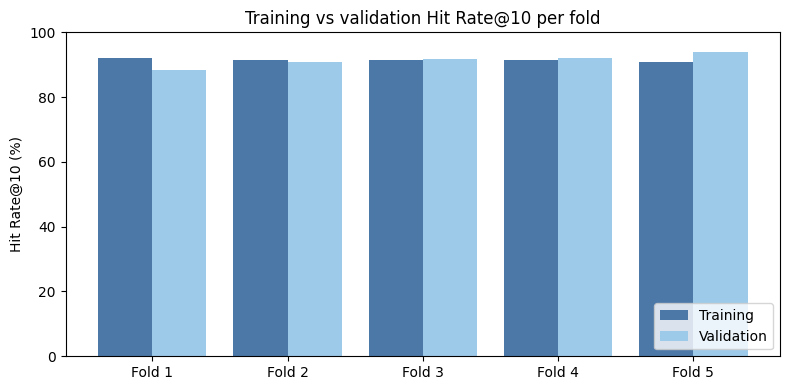

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(cv))
ax.bar(x - 0.2, cv["Training Hit@10"] * 100, width=0.4, label="Training", color="#4c78a8")
ax.bar(x + 0.2, cv["Validation Hit@10"] * 100, width=0.4, label="Validation", color="#9ecae9")
ax.set_xticks(x, [f"Fold {i}" for i in cv.Fold])
ax.set_ylim(0, 100); ax.set_ylabel("Hit Rate@10 (%)")
ax.set_title("Training vs validation Hit Rate@10 per fold")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## How to read this